# The Virtual Brain (TVB): An Overview

## What is The Virtual Brain?
The Virtual Brain (TVB) is an open-source platform designed to simulate brain activity using computational models. It integrates real neuroimaging data with mathematical simulations to better understand brain function and neurological disorders.

In [46]:
%pip install tvb-library
%pip install tvb-framework

In [47]:
from tvb.simulator.lab import *
import numpy as np
import matplotlib.pyplot as plt
import time as tm

A basic simulation consists of five main components, each of these components is an object within TVB:

- **Model**, which is, at its core, a set of differential equations describing the local neuronal dynamics;
- **Connectivity**, represents the large scale structural connectivity of the brain, ie white-matter tracts;
- **Coupling**, is a function that is used to join the local Model dynamics at distinct locations over the connections described in Connectivity;
- **Integrator**, is the integration scheme that will be applied to the coupled set of differential equations;
- **Monitors**, one or more Monitors can be attached to a simulation, they act to record the output from the Simulator.

All of these components are brought together in a **Simulator** object, which is then used to run a simulation.

### Model

In [48]:
dir(models)

['CoombesByrne',
 'CoombesByrne2D',
 'DecoBalancedExcInh',
 'DumontGutkin',
 'Enum',
 'Epileptor',
 'Epileptor2D',
 'EpileptorCodim3',
 'EpileptorCodim3SlowMod',
 'EpileptorRestingState',
 'GastSchmidtKnosche_SD',
 'GastSchmidtKnosche_SF',
 'Generic2dOscillator',
 'Hopfield',
 'JansenRit',
 'KIonEx',
 'Kuramoto',
 'LarterBreakspear',
 'Linear',
 'Model',
 'ModelsEnum',
 'MontbrioPazoRoxin',
 'ReducedSetFitzHughNagumo',
 'ReducedSetHindmarshRose',
 'ReducedWongWang',
 'ReducedWongWangExcInh',
 'SupHopf',
 'WilsonCowan',
 'ZerlautAdaptationFirstOrder',
 'ZerlautAdaptationSecondOrder',
 'ZetterbergJansen',
 '__builtins__',
 '__cached__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__file__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__loader__',
 '__lt__',
 '__module__',
 '__name__',
 '__ne__',
 '__new__',
 '__package__',
 '__path__',
 '__reduce__',
 '__reduce_


\begin{align*} \tau \dot{x}(t) &= -z(t) + \phi(z(t)) \\ \phi(x) &= \frac{c}{1-exp(-a (x-b))} \end{align*}

In [49]:
# choose the model from the TVB library
wilson_cowan = models.WilsonCowan()
wilson_cowan

In [50]:
wilson_cowan.theta_e

array([0.])

In [51]:
# see defaults
wilson_cowan.tau_e
# change a parameters
wilson_cowan.tau_i = np.array(5.)

**Generic 2-dimensional Oscillator** model:

\begin{align}
\dot{V} &= d \, \tau (-f V^3 + e V^2 + g V + \alpha W + \gamma I), \\
                \dot{W} &= \dfrac{d}{\tau}\,\,(c V^2 + b V - \beta W + a).
\end{align}

In [52]:
# set it to the limit-cycle regime with low amplitude at  𝑎=1.74
oscilator = models.Generic2dOscillator(a=np.array(1.740))

### Connectivity

Our neural mass models, each representing a brain region (**node**), are interconnected based on a structural connectivity framework that specifies the distances between nodes and the strengths of their connections.

In [53]:
# load standard connectome
conn = connectivity.Connectivity.from_file()

2026-05-14 16:45:38,993 - WARNING - tvb.basic.readers - File 'hemispheres' not found in ZIP.


In [54]:
conn.region_labels

array(['rA1', 'rA2', 'rAMYG', 'rCCA', 'rCCP', 'rCCR', 'rCCS', 'rFEF',
       'rG', 'rHC', 'rIA', 'rIP', 'rM1', 'rPCI', 'rPCIP', 'rPCM', 'rPCS',
       'rPFCCL', 'rPFCDL', 'rPFCDM', 'rPFCM', 'rPFCORB', 'rPFCPOL',
       'rPFCVL', 'rPHC', 'rPMCDL', 'rPMCM', 'rPMCVL', 'rS1', 'rS2',
       'rTCC', 'rTCI', 'rTCPOL', 'rTCS', 'rTCV', 'rV1', 'rV2', 'rCC',
       'lA1', 'lA2', 'lAMYG', 'lCCA', 'lCCP', 'lCCR', 'lCCS', 'lFEF',
       'lG', 'lHC', 'lIA', 'lIP', 'lM1', 'lPCI', 'lPCIP', 'lPCM', 'lPCS',
       'lPFCCL', 'lPFCDL', 'lPFCDM', 'lPFCM', 'lPFCORB', 'lPFCPOL',
       'lPFCVL', 'lPHC', 'lPMCDL', 'lPMCM', 'lPMCVL', 'lS1', 'lS2',
       'lTCC', 'lTCI', 'lTCPOL', 'lTCS', 'lTCV', 'lV1', 'lV2', 'lCC'],
      dtype='<U128')

In [55]:
len(conn.region_labels)

76

In [56]:
conn.weights.shape

(76, 76)

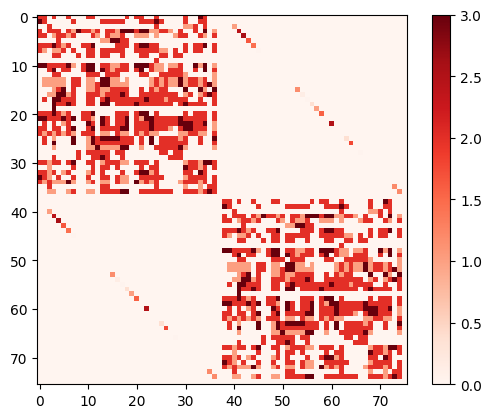

In [57]:
# connectivity weights
#plt.figure(figsize=(10,10))
plt.imshow(conn.weights, cmap='Reds')
#plt.xticks(ticks=np.arange(len(conn.region_labels)), labels=conn.region_labels, fontsize=8, rotation=90)
#plt.yticks(ticks=np.arange(len(conn.region_labels)), labels=conn.region_labels, fontsize=8)
plt.colorbar()

In [58]:
conn.centres

array([[ -9.885591, -47.084818,  -3.13936 ],
       [ -2.605247, -55.324507,  -7.065423],
       [  6.489431, -11.670519, -30.851544],
       [ 48.734149,  -2.004701,   8.019123],
       [-12.1714  ,  -6.494719,  25.361539],
       [-38.1525  , -13.054752,  -5.607666],
       [ 30.150795,  -4.286333, -31.136279],
       [ 30.400644, -33.753689,  34.832572],
       [ 36.159029, -35.084312, -18.938829],
       [-12.502286, -24.875165, -20.872351],
       [ 23.242996, -42.031295, -22.110624],
       [  9.822772, -44.114976, -18.760442],
       [  8.003023, -32.833685,  38.712349],
       [-22.152851, -56.734891,  16.852029],
       [-51.151034, -35.899675,  25.679908],
       [-43.927847,  -8.226723,  27.584594],
       [-30.092058, -33.534852,  43.097159],
       [ 54.048553, -37.427609,  12.535183],
       [ 59.995574, -14.366518,  26.025739],
       [ 59.612735,  -2.407101,  -0.844581],
       [ 59.286775,  -2.547348, -21.924281],
       [ 47.987255, -16.887697, -39.699154],
       [ 7

In [59]:
conn.tract_lengths.shape

(76, 76)

/tmp/ipykernel_29376/3798747253.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


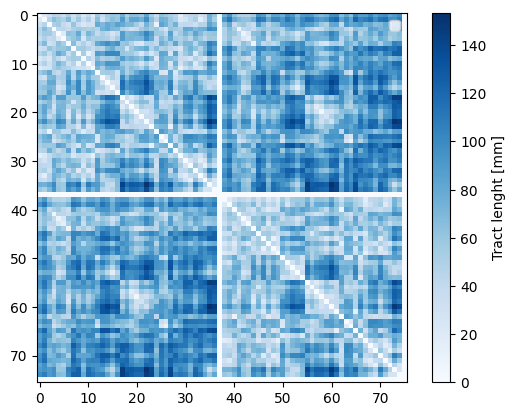

In [60]:
# connectivity tract lenghts
plt.imshow(conn.tract_lengths, cmap='Blues')
plt.colorbar(label='Tract lenght [mm]')
plt.legend()

In [61]:
# set speed of signal propagation through the network to 4.0 m/s
conn.speed = np.array([4.0])

### Coupling
The activity (state-variables) that have been propagated over the long-range Connectivity pass through these functions before entering the equations (Models())describing the local dynamics.

In [62]:
# choose a simple scaling function
G = np.array(0.0075)
conn_coupling = coupling.Scaling(a=G)

### Integrator
Now that we've defined our structure and dynamics we need to select an integration scheme. While TVB supports a number of schemes, for most purposes you should use either HeunDeterministic or HeunStochastic. Choose the integration step (dt), such that it is small enough for the integration to be numerically stable

In [63]:
# Initialise an Integrator scheme.
dt = 0.1   # Integration step [ms]

# heunint = integrators.HeunDeterministic(dt=dt)

# stochastic integrator (stochstic noise):
nsigma = 0.001   # Standard deviation of the noise
hiss = noise.Additive(nsig=np.array([nsigma, 0]))
heunint = integrators.HeunStochastic(dt=dt, noise=hiss)

### Monitors

Although there are Monitors which apply a biophysical measurement process to the simulated neural activity, such as EEG, MEG, etc, here we'll select two simple monitors just to show the idea.

The **Raw Monitor** takes no arguments and simply returns all the simulated data.
The **TemporalAverage Monitor** averages over a time window of length period returning one time point every period ms

In [64]:
#Initialise Monitors
mon_raw = monitors.Raw()
mon_tavg = monitors.TemporalAverage()
monitors = (mon_raw, mon_tavg)

### Simulator
The next step is to bring all these components together into a Simulator object.

In [65]:
sim = simulator.Simulator(model=oscilator, connectivity=conn, coupling = conn_coupling, integrator=heunint, monitors=monitors)

In [66]:
sim.configure()

### Run a simulation

In [67]:
# Perform the simulation.
tic = tm.time()

# this should take ~25s
(raw_time, raw_data), (tavg_time, tavg_data) = sim.run(simulation_length=10000.) # ~30s

'simulation required %0.3f seconds.' % (tm.time()-tic)

'simulation required 29.754 seconds.'

For each monitor, the simulation returns the time points and the associated data array.

The data arrays have shapes  𝑛(timepoints)×𝑛(variables of interest)×𝑛(regions)×𝑛(modes)
 .

In [68]:
f"raw_time: {raw_time.shape} | raw_data: {raw_data.shape}"

'raw_time: (100000,) | raw_data: (100000, 1, 76, 1)'

In [69]:
# Remove the dimensions with one element for easier indexing
raw = np.squeeze(np.array(raw_data))
tavg = np.squeeze(np.array(tavg_data))
raw.shape, tavg.shape

((100000, 76), (10000, 76))

In [70]:
# Normalize the time series for easier visualization
nraw = raw / (np.max(raw, 0) - np.min(raw, 0))
ntavg = tavg / (np.max(tavg, 0) - np.min(tavg, 0))

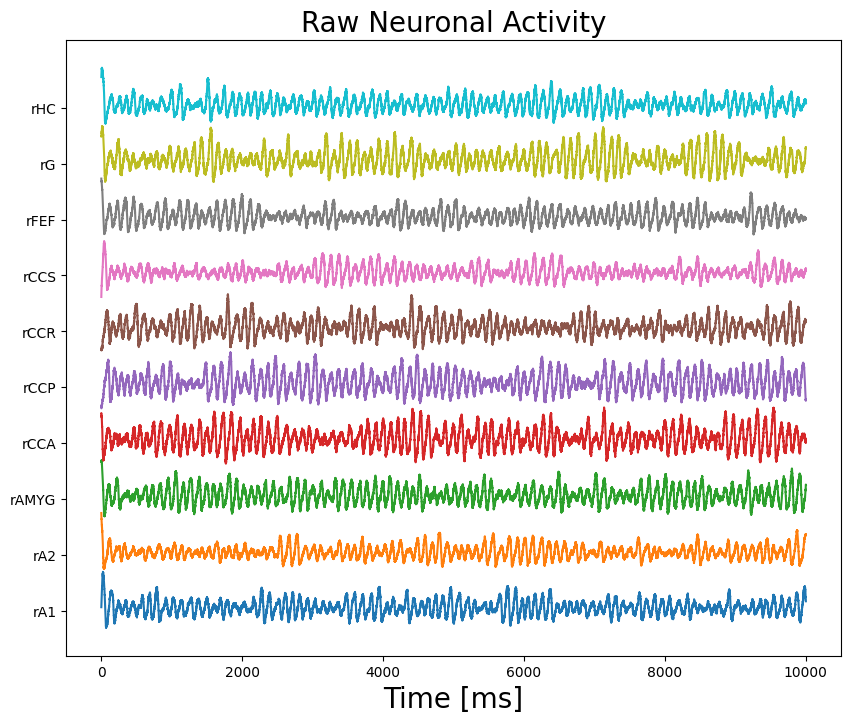

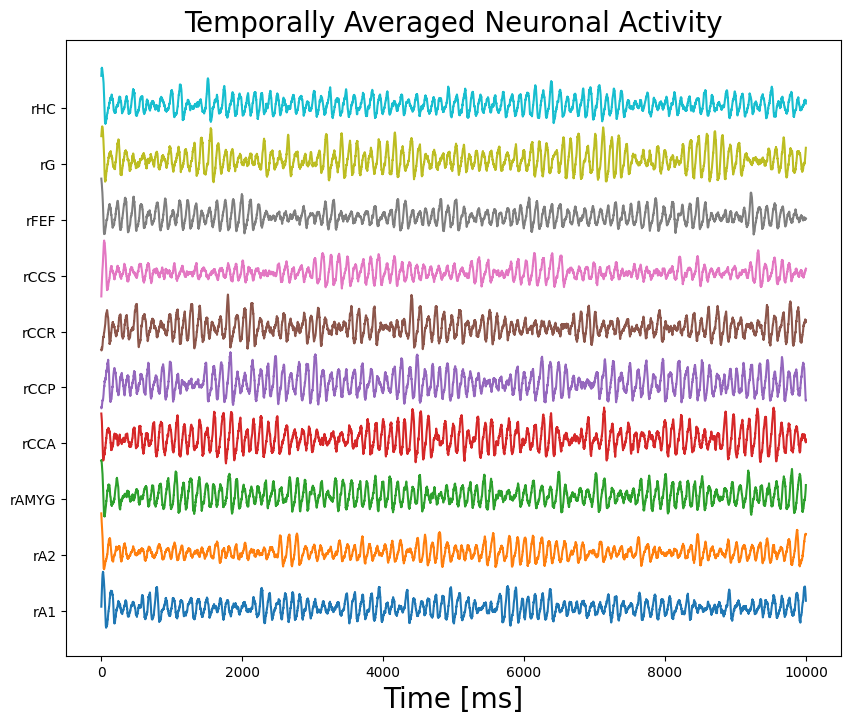

In [71]:
# Plot the raw time series
fig1 = plt.figure(figsize=(10,8))
plt.plot(raw_time[:], nraw[:, :10] + np.r_[:10])
plt.title('Raw Neuronal Activity', fontsize=20)
plt.xlabel('Time [ms]', fontsize=20)
plt.yticks(range(10), conn.region_labels[:10], fontsize=10)

# Plot the temporally averaged time series
fig2 = plt.figure(figsize=(10,8))
plt.plot(tavg_time[:], ntavg[:, :10] + np.r_[:10])
plt.title('Temporally Averaged Neuronal Activity', fontsize=20)
plt.xlabel('Time [ms]', fontsize=20)
plt.yticks(range(10), conn.region_labels[:10], fontsize=10)

plt.show()

### Stimulation

In The Virtual Brain (TVB), stimulation refers to the external perturbation of neural activity in specific brain regions or nodes within the brain network model. This is achieved using the Stimulus feature, which allows users to introduce external inputs to simulate the effects of electrical, magnetic, or sensory stimulation on the brain.

**Key Features of Stimulation in TVB**
- Targeted Stimulation:
Stimulation can be applied to specific nodes (brain regions) in the network. These nodes correspond to areas defined in the structural connectivity of the model.

- Customizable Stimuli:
Users can define the characteristics of the stimulus, such as:

  - Waveform: Includes predefined patterns like constant, sinusoidal, or pulse-shaped stimulation.
  - Amplitude: Determines the intensity of the stimulus.
  - Duration: Sets how long the stimulation is applied.
  - Frequency: Specifies the periodicity of oscillatory stimuli.

In [72]:
print(conn.region_labels[0])
print(conn.region_labels[7])

rA1
rFEF


In [73]:
# configure stimulus spatial pattern
weighting = np.zeros((conn.number_of_regions, ))
weighting[[0, 7, 13, 33, 42]] = np.array([2.0 ** -2, 2.0 ** -3, 2.0 ** -4, 2.0 ** -5, 2.0 ** -6])

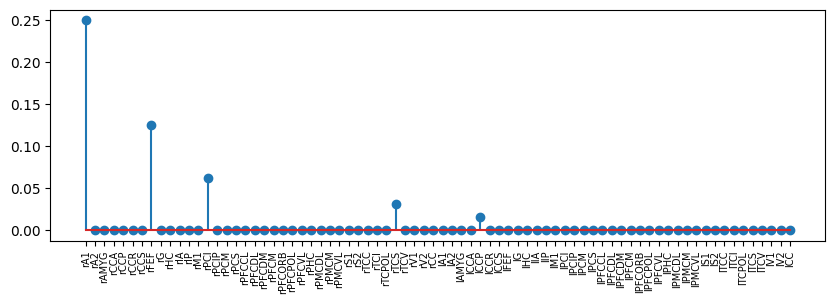

In [74]:
plt.figure(figsize=(10,3))
plt.stem(weighting)
plt.xticks(range(0, conn.number_of_regions), conn.region_labels, fontsize=7, rotation=90);

In [75]:
# define the temporal profile of the stimulation
eqn_t = equations.Gaussian()
eqn_t.parameters["midpoint"] = 4000.0 # ms
eqn_t.parameters["sigma"] = 200.0 # ms
eqn_t

In [76]:
stimulus = patterns.StimuliRegion(temporal=eqn_t,
                                  connectivity=conn,
                                  weight=weighting)

In [77]:
stimulus

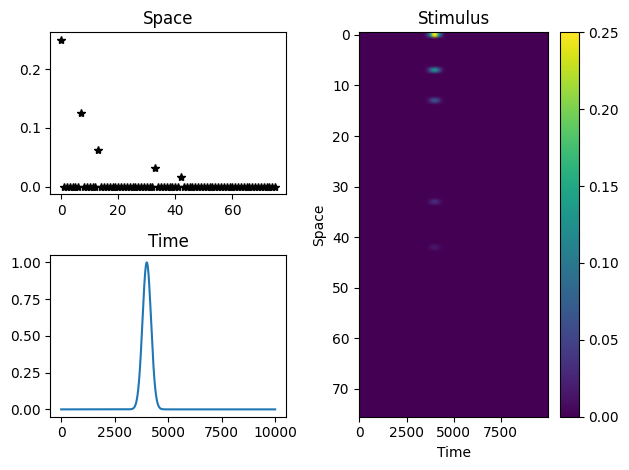

In [78]:
stimulus.configure_space()
stimulus.configure_time(np.arange(0., 10e3))
plot_pattern(stimulus)
plt.tight_layout()

In [79]:
sim = simulator.Simulator(
    model=models.Generic2dOscillator(a=np.array([0.5])),
    connectivity=conn,
    coupling=coupling.Linear(a=np.array([0.0126])),
    integrator=integrators.HeunDeterministic(dt=0.5),
    stimulus=stimulus,
    simulation_length=10e3,
).configure()

out = sim.run()
(tavg_time, tavg_data), = out

2026-05-14 16:46:12,303 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration


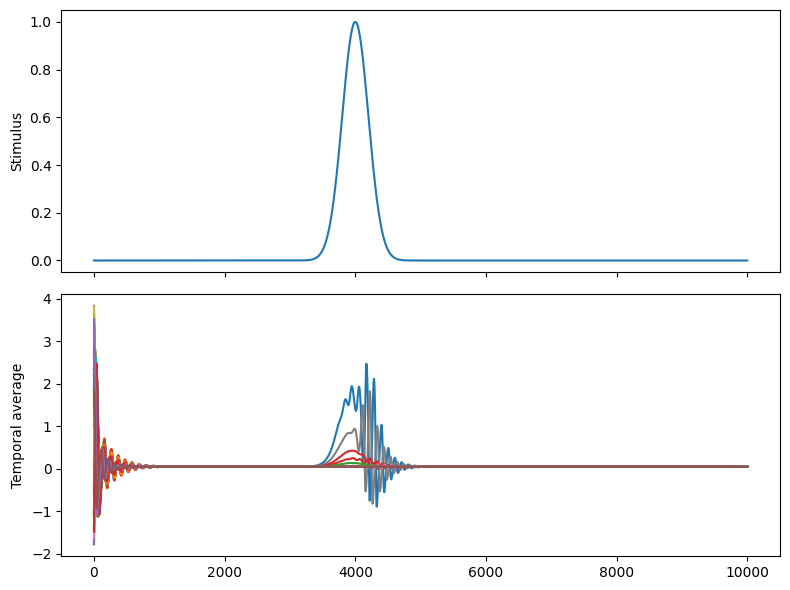

In [80]:
fig, axs = plt.subplots(nrows=2, sharex=True, figsize=(8,6))

ax = axs[0]
ax.plot(sim.stimulus.time[0,], sim.stimulus.temporal_pattern[0])
ax.set(ylabel="Stimulus")

ax = axs[1]
ax.plot(tavg_time, tavg_data[:, 0, :, 0])
ax.set(ylabel="Temporal average")

#for ax in axs:
#    ax.axvline(x=25000, c='k', ls=':')

fig.tight_layout()

### Stimulus propagation

Stimulating a single area to observe how the signal propagates from it to other brain regions.

In [81]:
# select LH primary motor cortex example 'lM1'
conn.region_labels[50]

np.str_('lM1')

In [82]:
# number of regions in the connectivity
weighting = np.zeros((76, ))

# attribution of a stimulus intensity in the targeted region
weighting[[50]] = 0.1

In [83]:
# Pulse Train type of stimulus
eqn_t = equations.PulseTrain()

# onset of the stimulus at 1500 ms
eqn_t.parameters['onset'] = 1500

# repetition of the stimulus every 1000 ms
eqn_t.parameters['T'] = 1000.0

# length of the stimulus of 50 ms
eqn_t.parameters['tau'] = 50.0

In [84]:
stimulus = patterns.StimuliRegion(
    temporal=eqn_t,
    connectivity=conn,
    weight=weighting)

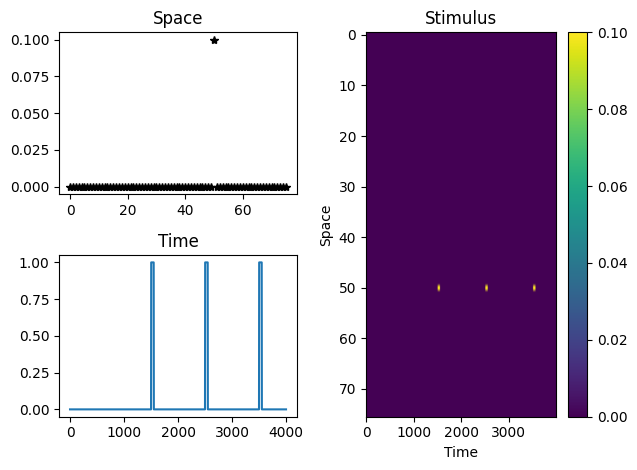

In [85]:
# configure space and time
stimulus.configure_space()
stimulus.configure_time(np.arange(0., 4e3, 1))

# plot the repetitive pulse train stimulus targetting the region selected
plot_pattern(stimulus)
plt.tight_layout()

In [86]:
sim = simulator.Simulator(

    model=models.Generic2dOscillator(a=np.array([0.3]), tau=np.array([2])),
    # dynamic system model describing one neural mass (m=1) with two state variables (n=2)

    connectivity=conn,
    # connectivity defined previously (here default TVB connectivity)

    coupling=coupling.Difference(a=np.array([7e-4])),
    # difference coupling function between pre and post synaptic activity of the form

    integrator=integrators.HeunStochastic(dt=0.5, noise=noise.Additive(nsig=np.array([5e-5]))),
    # example of a predictor-corrector method with noise addition

    stimulus=stimulus,
    # implementing the stimulus defined previously

    simulation_length=4e3,
    # length of the simulation in ms

).configure()

(tavg_time, tavg_data),  = sim.run()

Text(0.5, 0, 'Time (ms)')

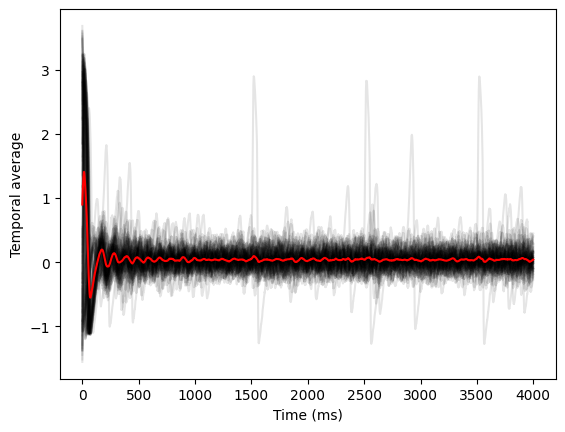

In [87]:
# propagation of the stimulus in the cortical regions
plt.figure()

# individual region time series superposed in black
plt.plot(tavg_time, tavg_data[:, 0, :, 0], 'k', alpha=0.1)

# time series mean in red
plt.plot(tavg_time, tavg_data[:, 0, :, 0].mean(axis=1), 'r', alpha=1)
plt.ylabel("Temporal average")
plt.xlabel('Time (ms)')

In [88]:
def plot_surface_mpl(vtx,tri,data=None,rm=None,reorient='tvb',view='superior',
                     shaded=False,ax=None,figsize=(6,4), title=None,
                     lthr=None,uthr=None, nz_thr = 1E-20,
                     shade_kwargs = {'edgecolors': 'k', 'linewidth': 0.1,
                                     'alpha': None, 'cmap': 'coolwarm',
                                     'vmin': None, 'vmax': None}):
  """
  Parameters
  ----------

  vtx           : N vertices x 3 array of surface vertex xyz coordinates

  tri           : N faces x 3 array of surface faces

  data          : array of numbers to colour surface with

  rm            : region mapping - N vertices x 1 array with (up to) N
                  regions unique values; each element specifies which
                  region the corresponding surface vertex is mapped to

  reorient      : modify the vertex coordinate frame and/or orientation
                  so that the same default rotations can subsequently be
                  used for image views

  view          : specify viewing angle

  lthr/uthr     : lower/upper thresholds - set to zero any datapoints below /
                  above these values

  nz_thr        : near-zero threshold - set to zero all datapoints with absolute
                  values smaller than this number

  shade_kwargs  : dictionary specifiying shading options

  ax            : figure axis

  figsize       : figure size (ignore if ax provided)

  title         : text string to place above figure
  """


  vtx,tri = vtx.copy(),tri.copy()
  if data is not None: data = data.copy()


                                    # 1. Set the viewing angle

  if reorient == 'tvb':
    # TVB default brain coordinates are yxz
    vtx = np.array([vtx[:,1],vtx[:,0],vtx[:,2]]).T.copy()

    # reflect in the x axis
    vtx[:,0]*=-1

    # rotations for standard view options
  if   view == 'lh_lat'    : rots =  [(0,-90),(1,90)  ]
  elif view == 'lh_med'    : rots =  [(0,-90),(1,-90) ]
  elif view == 'rh_lat'    : rots =  [(0,-90),(1,-90) ]
  elif view == 'rh_med'    : rots =  [(0,-90),(1,90)  ]
  elif view == 'superior'  : rots =   None
  elif view == 'inferior'  : rots =   (1,180)
  elif view == 'anterior'  : rots =   (0,-90)
  elif view == 'posterior' : rots =  [(0, -90),(1,180)]
  elif (type(view) == tuple) or (type(view) == list): rots = view

    # apply rotations
  if rots is None: rotmat = np.eye(3)
  else:            rotmat = get_combined_rotation_matrix(rots)
  vtx = np.dot(vtx,rotmat)



                                    # 2. Sort out the data


    # no data: plot a vector of 1s
    # region data: create corresponding surface vector
  if data is None:
    data = np.ones(vtx.shape[0])
  elif data.shape[0] != vtx.shape[0]:
    data = np.array([data[r] for r in rm])

    # apply thresholds
  if uthr: data *= (data < uthr)
  if lthr: data *= (data > lthr)
  data *= (np.abs(data) > nz_thr)


                                    # 3. Create the surface triangulation object

  x,y,z = vtx.T
  tx,ty,tz = vtx[tri].mean(axis=1).T
  tr = Triangulation(x,y,tri[np.argsort(tz)])


                                    # 4. Make the figure

  if ax is None: fig, ax = plt.subplots(figsize=figsize)
  tc = ax.tripcolor(tr, np.squeeze(data), **shade_kwargs)

  ax.set_aspect('equal')
  ax.axis('off')

  if title is not None: ax.set_title(title)


def get_combined_rotation_matrix(rotations):
  '''Return a combined rotation matrix from a dictionary of rotations around
     the x,y,or z axes'''
  rotmat = np.eye(3)

  if type(rotations) is tuple: rotations = [rotations]
  for r in rotations:
    newrot = get_rotation_matrix(r[0],r[1])
    rotmat = np.dot(rotmat,newrot)
  return rotmat


def get_rotation_matrix(rotation_axis, deg):

  '''Return rotation matrix in the x,y,or z plane'''
  th = -deg * (np.pi/180) # convert degrees to radians

  if rotation_axis == 0:
    return np.array( [[    1,         0,         0    ],
                      [    0,      np.cos(th),   -np.sin(th)],
                      [    0,      np.sin(th),    np.cos(th)]])
  elif rotation_axis ==1:
    return np.array( [[   np.cos(th),    0,        np.sin(th)],
                      [    0,         1,          0    ],
                      [  -np.sin(th),    0,        np.cos(th)]])
  elif rotation_axis ==2:
    return np.array([[   np.cos(th),  -np.sin(th),     0    ],
                     [    np.sin(th),   np.cos(th),     0   ],
                     [     0,         0,          1   ]])

The initial stimulus is on between [1500,1550] ms.

We will plot the evolution of the propagation of this initial stimulus on the brain surface

/tmp/ipykernel_29376/24675739.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = copy.copy(mpl.cm.get_cmap("Blues"))


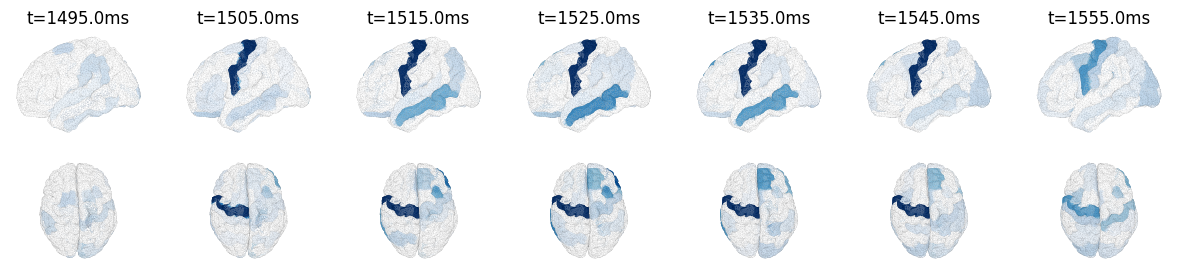

In [89]:
import copy
import matplotlib as mpl
from matplotlib.tri import Triangulation
ctx = cortex.Cortex.from_file()
# object Cortex: mesh surface defining 2D representation of convoluted cortical surface embedded in 3D space

ctx.region_mapping_data.connectivity=conn

vtx,tri,rm = ctx.vertices,ctx.triangles,ctx.region_mapping
# vtx: vertices
# tri: triangles
# rm: region mapping

fig, ax = plt.subplots(ncols=7, nrows=2,figsize=(15,3))
#cmap = cm.Blues
cmap = copy.copy(mpl.cm.get_cmap("Blues"))
cmap.set_under(color='w')
kws = {'edgecolors': 'k', 'vmin': 0.1, 'cmap': cmap,
       'vmax': 0.6, 'alpha': None, 'linewidth': 0.01}

ts = [1495, 1505, 1515, 1525, 1535, 1545, 1555]
# time states to plot

for t_it,t in enumerate(ts):

    dat = np.absolute(tavg_data[t, 0, :, 0])

    plot_surface_mpl(vtx=vtx, tri=tri,data=dat,rm=rm,ax=ax[0][t_it],
                   shade_kwargs=kws,
                   view='lh_lat')   # lateral view

    plot_surface_mpl(vtx=vtx,tri=tri,data=dat,rm=rm,ax=ax[1][t_it],
                   shade_kwargs=kws,
                   view='superior') # above view


    ax[0][t_it].set_title('t=%1.1fms' %t)

The left/right primary motor cortex region targeted corresponds well to the area with the highest activity impacted by the initial stimulus (dark blue).

The stimulus activity propagation to other areas (premotor areas, sensory areas) is well visible.